# 02 - Exploratory data analysis



**Purpose:** get to know the cleaned data: volumes over time, seasonality, order values, cities, customers, restaurants, delivery times, ratings and payment mix.

**Input:** `Forkly/Data_clean/*.csv` (output of 01_cleaning), `Forkly/src/theme.py` (chart style)
**Output:** charts in `Forkly/output/figures/`



## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

# works whether the notebook runs from the Forkly folder or from Forkly/notebooks
BASE = Path.cwd() if (Path.cwd() / "Data").exists() else Path.cwd().parent
CLEAN_DIR = BASE / "Data_clean"
FIG_DIR = BASE / "output" / "figures"
TAB_DIR = BASE / "output" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

# shared chart style (Forkly/src/theme.py)
sys.path.append(str(BASE / "src"))
from theme import *
apply_theme()

In [2]:
DATE_COLS = {
    "calendar": ["date"],
    "cities": ["launch_date"],
    "weather_daily": ["date"],
    "customers": ["signup_date", "signup_month"],
    "restaurants": ["onboarded_date", "offboarded_date"],
    "couriers": ["join_date"],
    "promotions": ["start_date", "end_date"],
    "subscriptions": ["start_date", "end_date"],
    "orders": ["order_datetime", "order_date", "month"],
    "deliveries": ["pickup_datetime", "dropoff_datetime"],
    "reviews": ["review_datetime"],
    "support_tickets": ["created_datetime", "resolved_datetime"],
    "marketing_spend": ["date"],
}

df = {}
for path in sorted(CLEAN_DIR.glob("*.csv")):
    if path.stem != "cleaning_log":
        df[path.stem] = pd.read_csv(path, parse_dates=DATE_COLS.get(path.stem, []))

orders, order_items, deliveries = df["orders"], df["order_items"], df["deliveries"]
customers, restaurants, reviews = df["customers"], df["restaurants"], df["reviews"]
cities, couriers, tickets = df["cities"], df["couriers"], df["support_tickets"]
mkt, weather, subs, promos = df["marketing_spend"], df["weather_daily"], df["subscriptions"], df["promotions"]

print({k: f"{len(v):,}" for k, v in df.items()})

{'calendar': '1,826', 'cities': '12', 'couriers': '5,369', 'customers': '45,000', 'deliveries': '282,862', 'marketing_spend': '10,956', 'menu_items': '18,454', 'order_items': '662,291', 'orders': '300,000', 'promotions': '120', 'restaurants': '2,889', 'reviews': '132,720', 'subscriptions': '15,287', 'support_tickets': '13,365', 'weather_daily': '21,912'}


In [3]:
# one order-level table with the most used columns joined in
od = (orders
      .merge(cities[["city_id", "city", "country"]], on="city_id", how="left")
      .merge(restaurants[["restaurant_id", "cuisine", "price_tier", "is_chain"]], on="restaurant_id", how="left")
      .merge(deliveries[["order_id", "courier_id", "distance_km", "delivery_minutes", "promised_minutes",
                         "minutes_vs_promise", "is_late", "weather_condition"]], on="order_id", how="left")
      .merge(reviews[["order_id", "food_rating", "delivery_rating"]], on="order_id", how="left"))
done = od[~od["is_cancelled"]]          # delivered + failed, used for GMV
YEARS = [2021, 2022, 2023, 2024, 2025]
print(f"{len(od):,} orders, {len(done):,} not cancelled")

300,000 orders, 282,862 not cancelled


## 2. Data overview

In [4]:
overview = pd.DataFrame({
    "rows": {k: len(v) for k, v in df.items()},
    "columns": {k: v.shape[1] for k, v in df.items()},
}).sort_values("rows", ascending=False)
overview

,rows,columns
order_items,662291,6
orders,300000,25
deliveries,282862,15
reviews,132720,8
customers,45000,11
weather_daily,21912,5
menu_items,18454,5
subscriptions,15287,8
support_tickets,13365,10
marketing_spend,10956,6


In [5]:
print("Orders from", orders["order_datetime"].min(), "to", orders["order_datetime"].max())
orders[["items_subtotal", "delivery_fee", "service_fee", "discount_amount", "tip_amount", "total_amount"]].describe().T

Orders from 2021-01-01 08:51:25 to 2025-12-31 23:49:48


,count,mean,std,min,25%,50%,75%,max
items_subtotal,"300,000.00",25.54,18.10,1.50,12.50,21.40,33.89,282.07
delivery_fee,"300,000.00",2.42,1.06,0.00,2.27,2.58,2.96,5.99
service_fee,"300,000.00",0.77,0.46,0.00,0.49,0.99,0.99,1.78
discount_amount,"300,000.00",0.79,1.89,0.00,0.00,0.00,0.00,37.02
tip_amount,"300,000.00",0.45,0.91,0.00,0.00,0.00,0.50,5.00
total_amount,"300,000.00",28.40,17.82,2.57,15.43,24.08,36.54,285.35


## 3. Orders and GMV over time

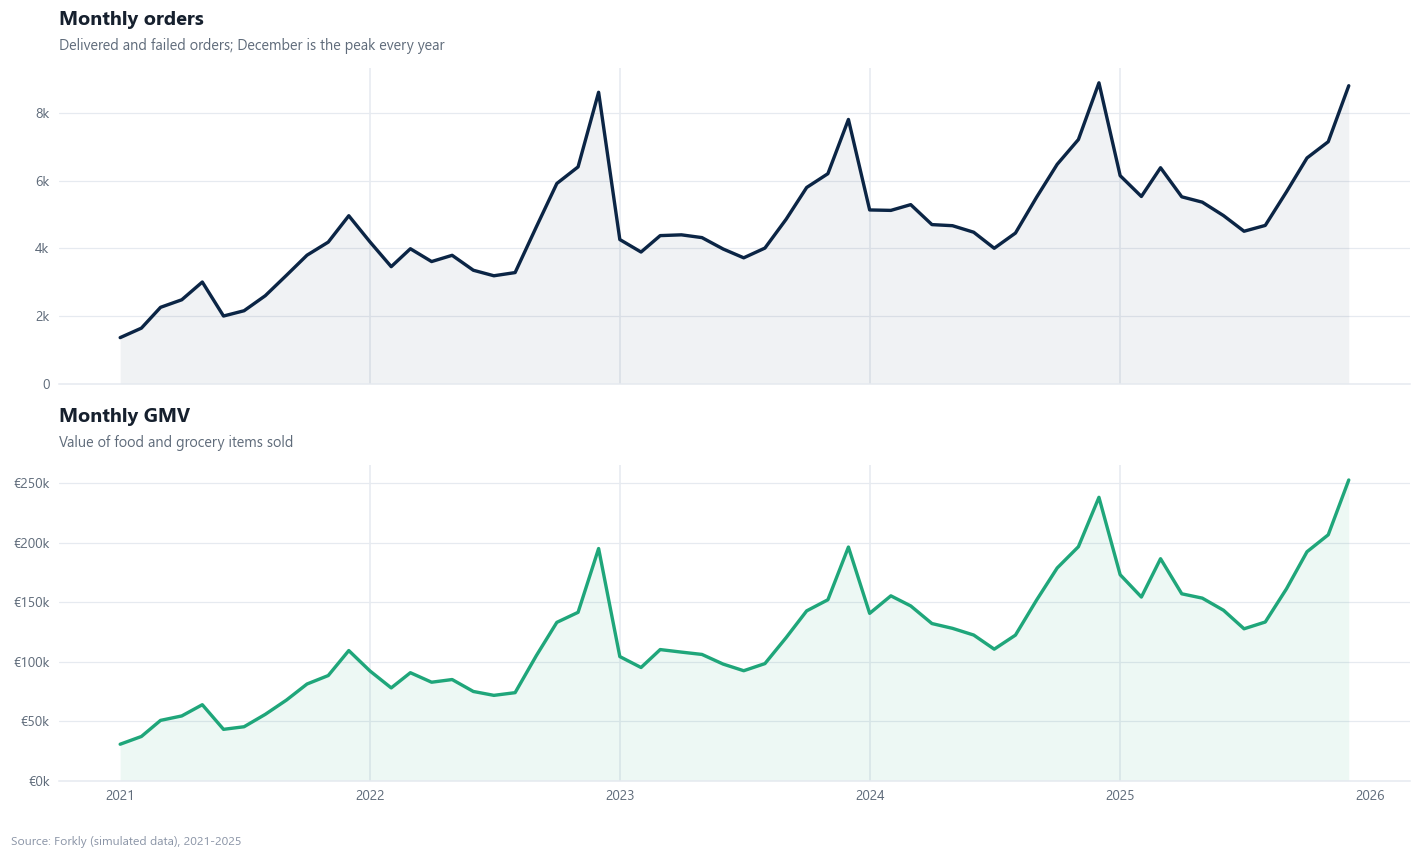

In [6]:
monthly = done.groupby("month").agg(orders=("order_id", "size"), gmv=("items_subtotal", "sum"))

fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True)
axes[0].plot(monthly.index, monthly["orders"], color=NAVY)
axes[0].fill_between(monthly.index, monthly["orders"], color=NAVY, alpha=0.06)
axes[0].yaxis.set_major_formatter(thousands)
title(axes[0], "Monthly orders", "Delivered and failed orders; December is the peak every year")

axes[1].plot(monthly.index, monthly["gmv"], color=GREEN)
axes[1].fill_between(monthly.index, monthly["gmv"], color=GREEN, alpha=0.08)
axes[1].yaxis.set_major_formatter(eur_k)
title(axes[1], "Monthly GMV", "Value of food and grocery items sold")

for ax in axes:
    ax.set_ylim(bottom=0)
    for y in YEARS[1:]:
        ax.axvline(pd.Timestamp(f"{y}-01-01"), color=GRID, lw=1, zorder=0)
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "02_monthly_orders_gmv.png")
plt.show()

In [7]:
yearly = done.groupby("year").agg(orders=("order_id", "size"), gmv=("items_subtotal", "sum"),
                                  customers=("customer_id", "nunique"))
yearly["gmv_growth_%"] = yearly["gmv"].pct_change() * 100
yearly["orders_growth_%"] = yearly["orders"].pct_change() * 100
yearly

,orders,gmv,customers,gmv_growth_%,orders_growth_%
year,,,,,
2021,33623,"728,358.01",10235,NaN,NaN
2022,54397,"1,224,139.97",20161,68.07,61.79
2023,57585,"1,423,775.07",21771,16.31,5.86
2024,65907,"1,823,040.95",25356,28.04,14.45
2025,71350,"2,040,859.89",28421,11.95,8.26


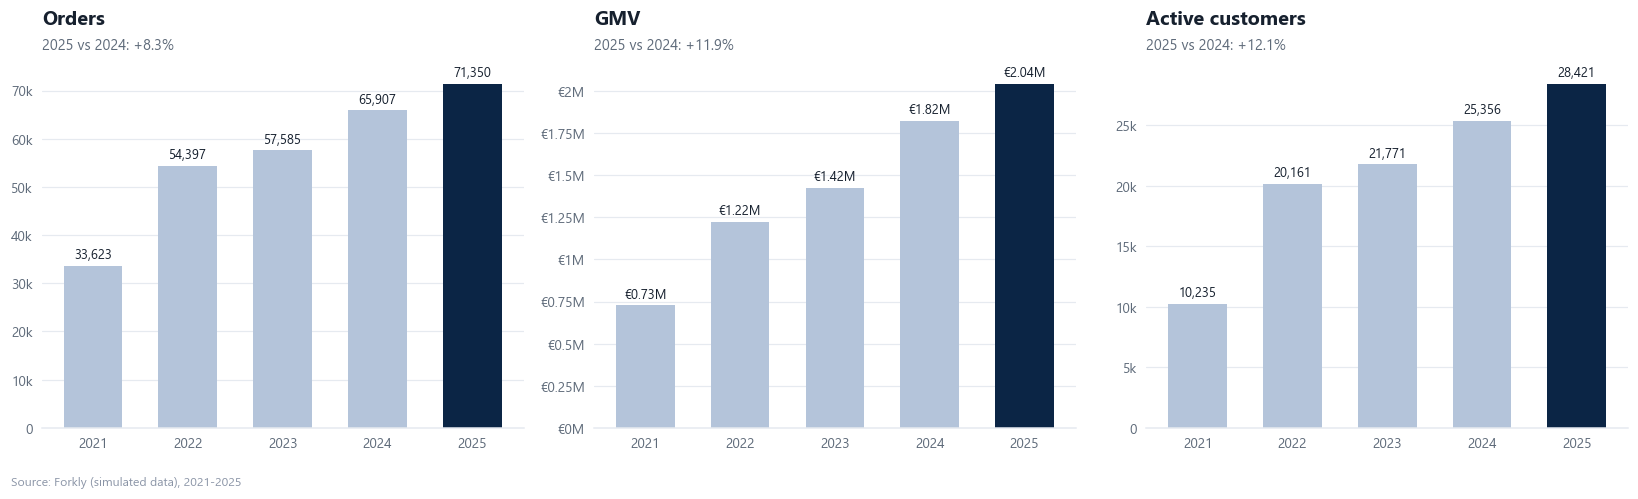

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
specs = [("orders", "Orders", thousands, lambda v: f"{v:,.0f}"),
         ("gmv", "GMV", eur_m, lambda v: f"€{v / 1e6:.2f}M"),
         ("customers", "Active customers", thousands, lambda v: f"{v:,.0f}")]
for ax, (col, name, axis_fmt, label_fmt) in zip(axes, specs):
    colors = [NAVY_LIGHT] * 4 + [NAVY]
    bars = ax.bar(yearly.index, yearly[col], color=colors, width=0.62)
    label_bars(ax, bars, label_fmt)
    ax.yaxis.set_major_formatter(axis_fmt)
    ax.set_xticks(yearly.index)
    growth = yearly[col].iloc[-1] / yearly[col].iloc[-2] - 1
    title(ax, name, f"2025 vs 2024: {growth:+.1%}")
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "02_yearly_totals.png")
plt.show()

## 4. Seasonality

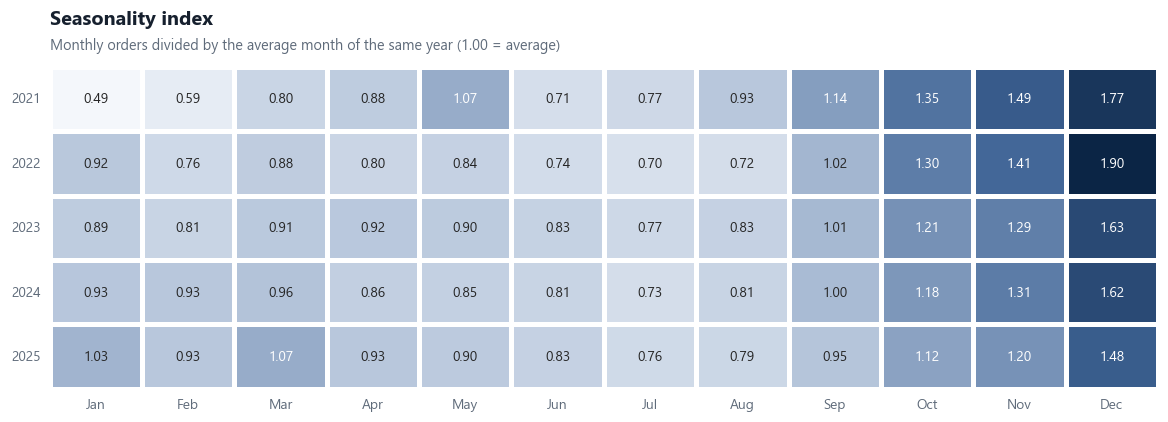

In [9]:
season = done.groupby(["year", done["order_datetime"].dt.month])["order_id"].size().unstack()
season = season.div(season.mean(axis=1), axis=0)   # 1.0 = average month of that year
season.columns = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(season, cmap=CMAP_NAVY, annot=True, fmt=".2f", cbar=False, linewidths=2, linecolor=BG,
            annot_kws={"fontsize": 9}, ax=ax)
clean_heatmap(ax)
title(ax, "Seasonality index", "Monthly orders divided by the average month of the same year (1.00 = average)")
ax.set_xlabel(""); ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
save_fig(fig, FIG_DIR / "02_month_seasonality.png")
plt.show()

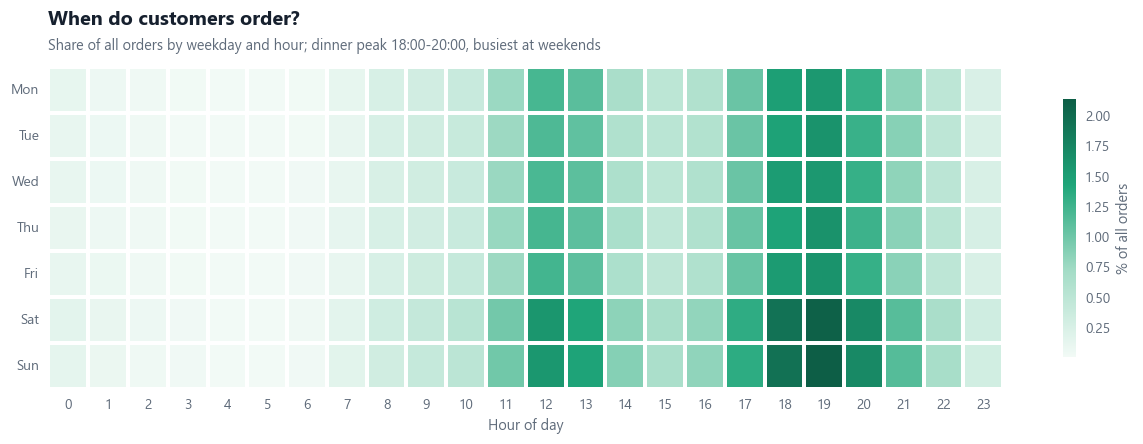

In [10]:
weekday_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
wh = (done.assign(weekday=done["order_datetime"].dt.strftime("%a"))
      .pivot_table(index="weekday", columns="hour", values="order_id", aggfunc="size")
      .reindex(weekday_order))
wh = wh / wh.values.sum() * 100

fig, ax = plt.subplots(figsize=(14, 3.8))
sns.heatmap(wh, cmap=CMAP_GREEN, cbar_kws={"label": "% of all orders", "shrink": 0.8}, linewidths=1.5,
            linecolor=BG, ax=ax)
clean_heatmap(ax)
title(ax, "When do customers order?", "Share of all orders by weekday and hour; dinner peak 18:00-20:00, busiest at weekends")
ax.set_xlabel("Hour of day"); ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
save_fig(fig, FIG_DIR / "02_weekday_hour.png")
plt.show()

## 5. Order value

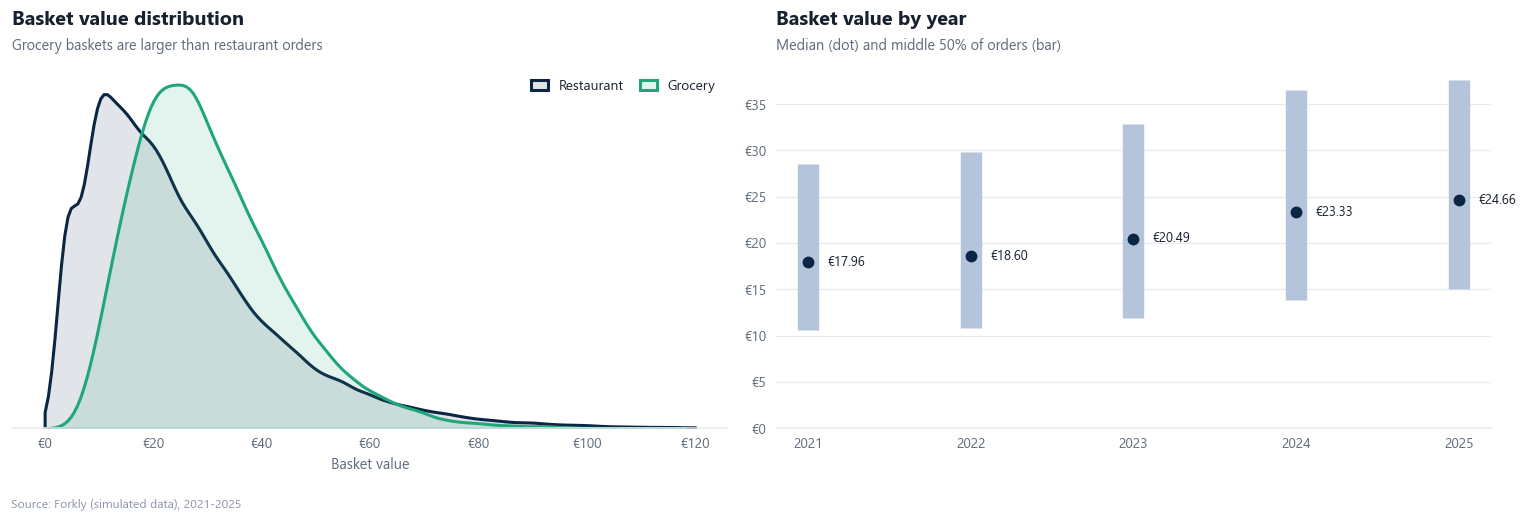

count               mean             median           
vertical   Grocery Restaurant Grocery Restaurant Grocery Restaurant
year                                                               
2021           NaN  33,623.00     NaN      21.66     NaN      17.96
2022           NaN  54,397.00     NaN      22.50     NaN      18.60
2023           NaN  57,585.00     NaN      24.72     NaN      20.49
2024      5,394.00  60,513.00   30.09      27.44   27.60      22.84
2025     11,272.00  60,078.00   30.76      28.20   28.45      23.64

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for vert, color in [("Restaurant", NAVY), ("Grocery", GREEN)]:
    sns.kdeplot(done.loc[done["vertical"] == vert, "items_subtotal"], clip=(0, 120), color=color,
                fill=True, alpha=0.12, lw=2, label=vert, ax=axes[0])
axes[0].xaxis.set_major_formatter(eur)
axes[0].set_xlabel("Basket value"); axes[0].set_ylabel(""); axes[0].set_yticks([])
legend_top(axes[0], ncol=2)
title(axes[0], "Basket value distribution", "Grocery baskets are larger than restaurant orders")

med = done.groupby("year")["items_subtotal"].quantile([0.25, 0.5, 0.75]).unstack()
axes[1].vlines(med.index, med[0.25], med[0.75], color=NAVY_LIGHT, lw=14)
axes[1].scatter(med.index, med[0.5], color=NAVY, s=60, zorder=3)
for x, v in zip(med.index, med[0.5]):
    axes[1].text(x + 0.12, v, fmt_eur(v), va="center", fontsize=8.5)
axes[1].yaxis.set_major_formatter(eur); axes[1].set_xticks(med.index); axes[1].set_ylim(0, None)
title(axes[1], "Basket value by year", "Median (dot) and middle 50% of orders (bar)")
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "02_order_value.png")
plt.show()

done.groupby(["year", "vertical"])["items_subtotal"].agg(["count", "mean", "median"]).unstack()

## 6. Cities

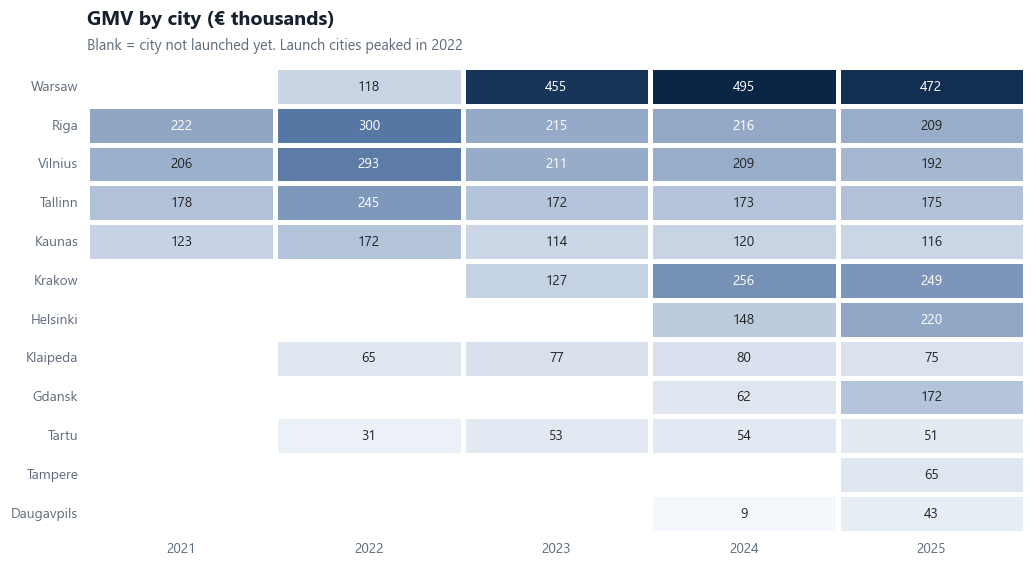

,city,country,launch_date,population
0,Vilnius,Lithuania,2021-01-01,590000
1,Kaunas,Lithuania,2021-01-01,300000
2,Riga,Latvia,2021-01-01,605000
3,Tallinn,Estonia,2021-01-01,455000
4,Klaipeda,Lithuania,2022-03-01,160000
5,Tartu,Estonia,2022-05-01,97000
6,Warsaw,Poland,2022-09-01,1860000
7,Krakow,Poland,2023-04-01,800000
8,Helsinki,Finland,2024-02-01,675000
9,Gdansk,Poland,2024-06-01,485000


In [12]:
city_year = done.pivot_table(index="city", columns="year", values="items_subtotal", aggfunc="sum", fill_value=0)
city_year = city_year.loc[city_year.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.heatmap(city_year / 1e3, cmap=CMAP_NAVY, annot=True, fmt=",.0f", cbar=False, linewidths=2, linecolor=BG,
            mask=city_year == 0, annot_kws={"fontsize": 9}, ax=ax)
clean_heatmap(ax)
title(ax, "GMV by city (€ thousands)", "Blank = city not launched yet. Launch cities peaked in 2022")
ax.set_xlabel(""); ax.set_ylabel("")
save_fig(fig, FIG_DIR / "02_city_year_gmv.png")
plt.show()

cities.sort_values("launch_date")[["city", "country", "launch_date", "population"]]

## 7. Customers

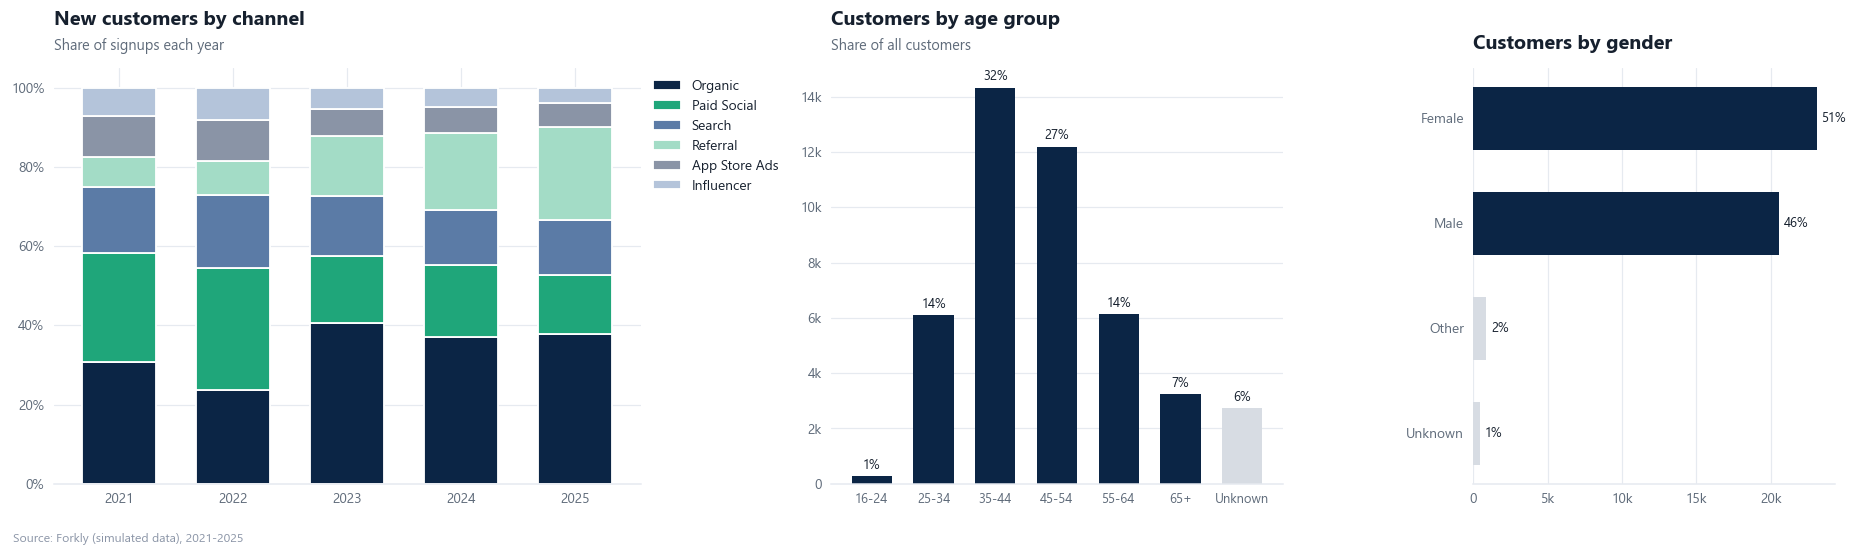

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.3, 1, 0.8]})

ch = customers.groupby(["signup_year", "acquisition_channel"]).size().unstack()
ch_share = ch.div(ch.sum(axis=1), axis=0) * 100
order = ch_share.mean().sort_values(ascending=False).index
ch_share[order].plot(kind="bar", stacked=True, ax=axes[0], width=0.65, edgecolor=BG, linewidth=1.2)
axes[0].yaxis.set_major_formatter(pct); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(bbox_to_anchor=(1, 1), loc="upper left")
title(axes[0], "New customers by channel", "Share of signups each year")

age = customers["age_group"].value_counts().reindex(["16-24", "25-34", "35-44", "45-54", "55-64", "65+", "Unknown"])
bars = axes[1].bar(age.index, age.values, color=[NAVY] * 6 + [GREY_LIGHT], width=0.65)
label_bars(axes[1], bars, lambda v: f"{v / age.sum():.0%}")
axes[1].yaxis.set_major_formatter(thousands); axes[1].tick_params(axis="x", labelsize=8.5)
title(axes[1], "Customers by age group", "Share of all customers")

g = customers["gender"].value_counts().sort_values()
bars = axes[2].barh(g.index, g.values, color=[GREY_LIGHT if i in ("Unknown", "Other") else NAVY for i in g.index], height=0.6)
label_hbars(axes[2], bars, lambda v: f"{v / g.sum():.0%}")
axes[2].xaxis.set_major_formatter(thousands); hbar_style(axes[2])
title(axes[2], "Customers by gender")
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "02_customers.png")
plt.show()

count   42,026.00
mean         7.14
std          5.40
min          1.00
25%          3.00
50%          6.00
75%          9.00
max         60.00
dtype: float64


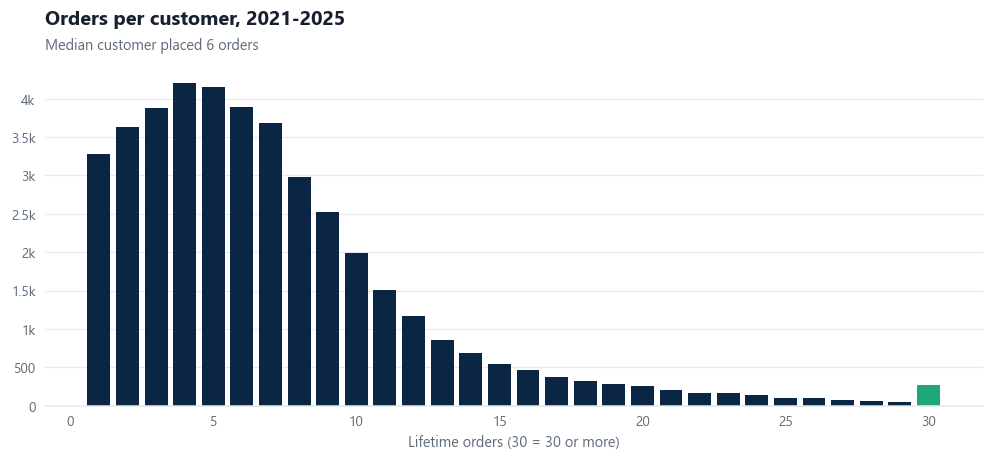

In [14]:
orders_per_customer = orders.groupby("customer_id").size()
print(orders_per_customer.describe())

fig, ax = plt.subplots(figsize=(11, 4))
counts = orders_per_customer.clip(upper=30).value_counts().sort_index()
ax.bar(counts.index, counts.values, color=[NAVY if i < 30 else GREEN for i in counts.index], width=0.8)
ax.yaxis.set_major_formatter(thousands); ax.set_xlabel("Lifetime orders (30 = 30 or more)")
title(ax, "Orders per customer, 2021-2025", f"Median customer placed {orders_per_customer.median():.0f} orders")
save_fig(fig, FIG_DIR / "02_orders_per_customer.png")
plt.show()

## 8. Restaurants and cuisines

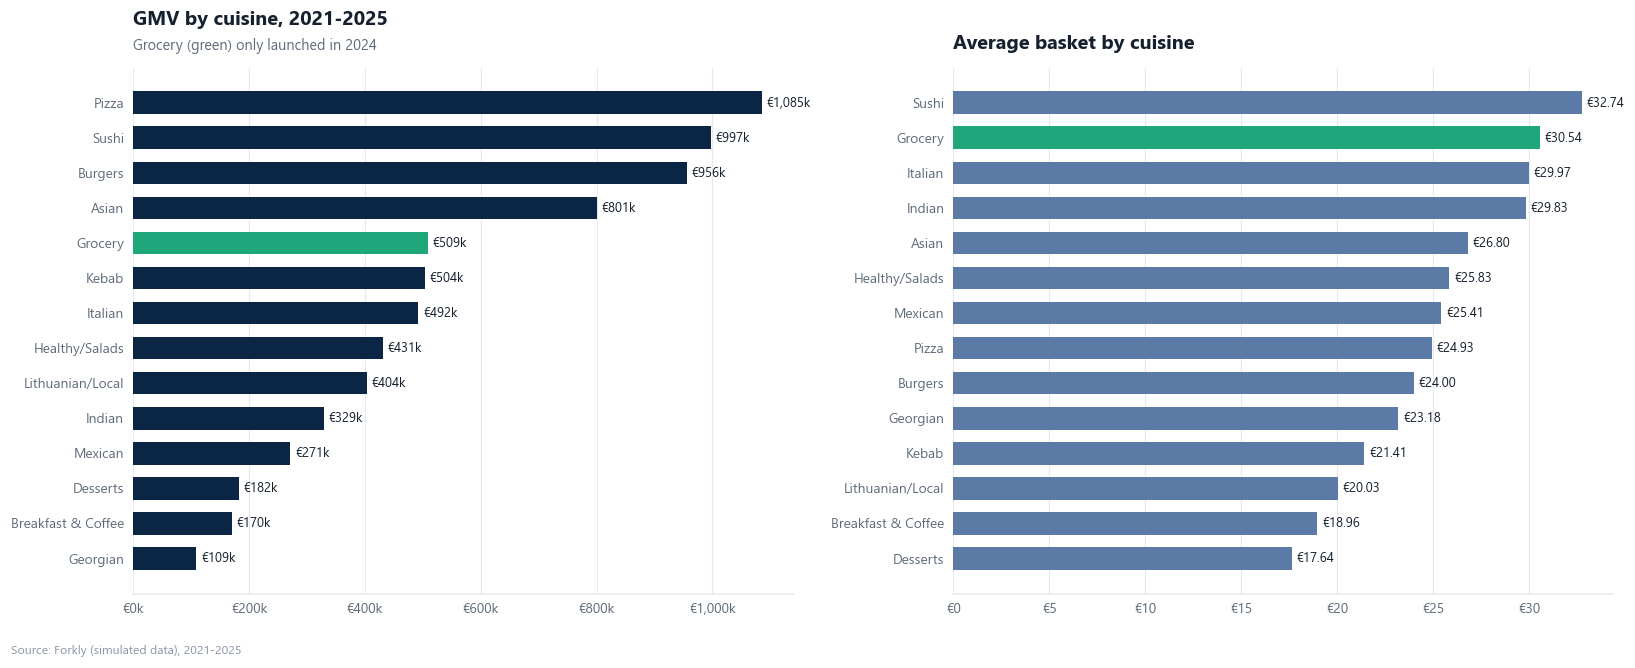

price_tier,1,2,3
vertical,,,
Grocery,0,112,0
Restaurant,1016,1272,489


In [15]:
cuisine = done.groupby("cuisine")["items_subtotal"].agg(gmv="sum", orders="size", aov="mean").sort_values("gmv")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
bars = axes[0].barh(cuisine.index, cuisine["gmv"], color=[GREEN if c == "Grocery" else NAVY for c in cuisine.index], height=0.65)
label_hbars(axes[0], bars, lambda v: f"€{v / 1e3:,.0f}k")
axes[0].xaxis.set_major_formatter(eur_k); hbar_style(axes[0])
title(axes[0], "GMV by cuisine, 2021-2025", "Grocery (green) only launched in 2024")

a = cuisine["aov"].sort_values()
bars = axes[1].barh(a.index, a.values, color=[GREEN if c == "Grocery" else STEEL for c in a.index], height=0.65)
label_hbars(axes[1], bars, lambda v: fmt_eur(v))
axes[1].xaxis.set_major_formatter(eur); hbar_style(axes[1])
title(axes[1], "Average basket by cuisine")
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "02_cuisines.png")
plt.show()

restaurants.groupby(["vertical", "price_tier"]).size().unstack(fill_value=0)

## 9. Delivery times

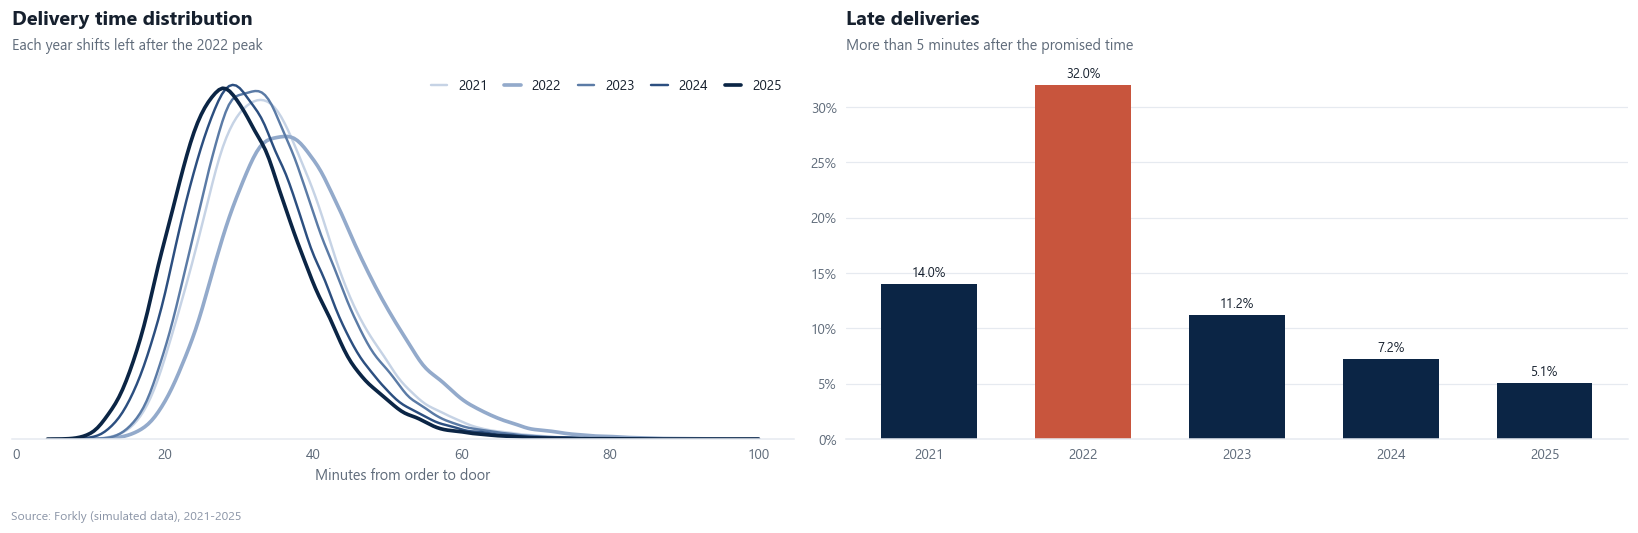

,mean,25%,50%,75%
year,,,,
2021,35.25,28.70,34.30,40.60
2022,39.13,31.70,37.90,45.20
2023,34.46,28.00,33.40,39.70
2024,32.38,26.00,31.40,37.70
2025,30.73,24.30,29.80,36.10


In [16]:
dl = done.dropna(subset=["delivery_minutes"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for y in YEARS:
    sns.kdeplot(dl.loc[dl["year"] == y, "delivery_minutes"], clip=(0, 100), color=YEAR_COLORS[y],
                lw=2.4 if y in (2022, 2025) else 1.6, label=str(y), ax=axes[0])
axes[0].set_xlabel("Minutes from order to door"); axes[0].set_ylabel(""); axes[0].set_yticks([])
legend_top(axes[0], ncol=5)
title(axes[0], "Delivery time distribution", "Each year shifts left after the 2022 peak")

late = dl.groupby("year")["is_late"].mean() * 100
bars = axes[1].bar(late.index, late.values, color=[ALERT if y == 2022 else NAVY for y in late.index], width=0.62)
label_bars(axes[1], bars, "{:.1f}%")
axes[1].yaxis.set_major_formatter(pct); axes[1].set_xticks(late.index)
title(axes[1], "Late deliveries", "More than 5 minutes after the promised time")
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "02_delivery_time.png")
plt.show()

dl.groupby("year")["delivery_minutes"].describe()[["mean", "25%", "50%", "75%"]]

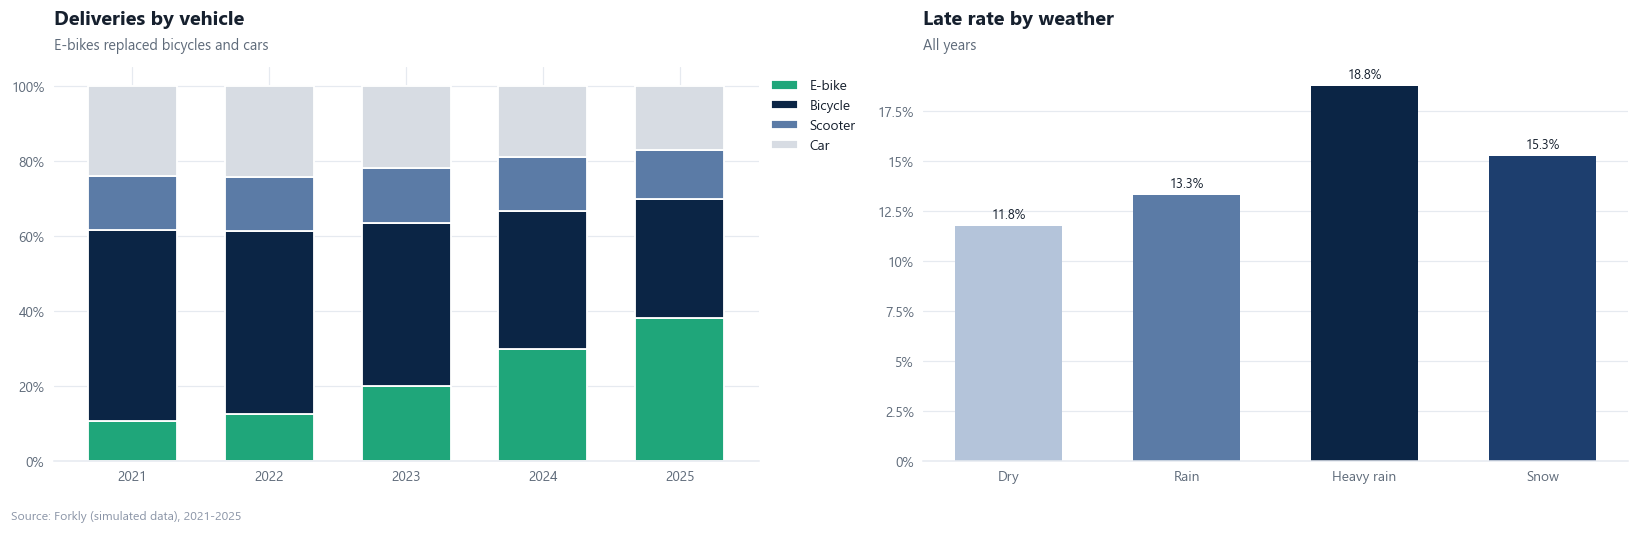

In [17]:
veh = dl.merge(couriers[["courier_id", "vehicle_type"]], on="courier_id", how="left")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
vy = veh.pivot_table(index="year", columns="vehicle_type", values="order_id", aggfunc="size")
vy = (vy.div(vy.sum(axis=1), axis=0) * 100)[["E-bike", "Bicycle", "Scooter", "Car"]]
vy.plot(kind="bar", stacked=True, ax=axes[0], width=0.65, edgecolor=BG, linewidth=1.2,
        color=[GREEN, NAVY, STEEL, GREY_LIGHT])
axes[0].yaxis.set_major_formatter(pct); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(bbox_to_anchor=(1, 1), loc="upper left")
title(axes[0], "Deliveries by vehicle", "E-bikes replaced bicycles and cars")

w = dl.groupby("weather_condition")["is_late"].mean().reindex(["Dry", "Rain", "Heavy rain", "Snow"]) * 100
bars = axes[1].bar(w.index, w.values, color=[NAVY_LIGHT, STEEL, NAVY, NAVY_2], width=0.6)
label_bars(axes[1], bars, "{:.1f}%")
axes[1].yaxis.set_major_formatter(pct)
title(axes[1], "Late rate by weather", "All years")
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "02_vehicle_weather.png")
plt.show()

## 10. Ratings

C:\Users\algir\AppData\Local\Temp\ipykernel_4292\2327820346.py:20: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Segoe UI.
  plt.tight_layout()
c:\Users\algir\Desktop\Projects\Python\Forkly\src\theme.py:178: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Segoe UI.
  fig.savefig(path)
c:\Users\algir\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Segoe UI.
  fig.canvas.print_figure(bytes_io, **kw)


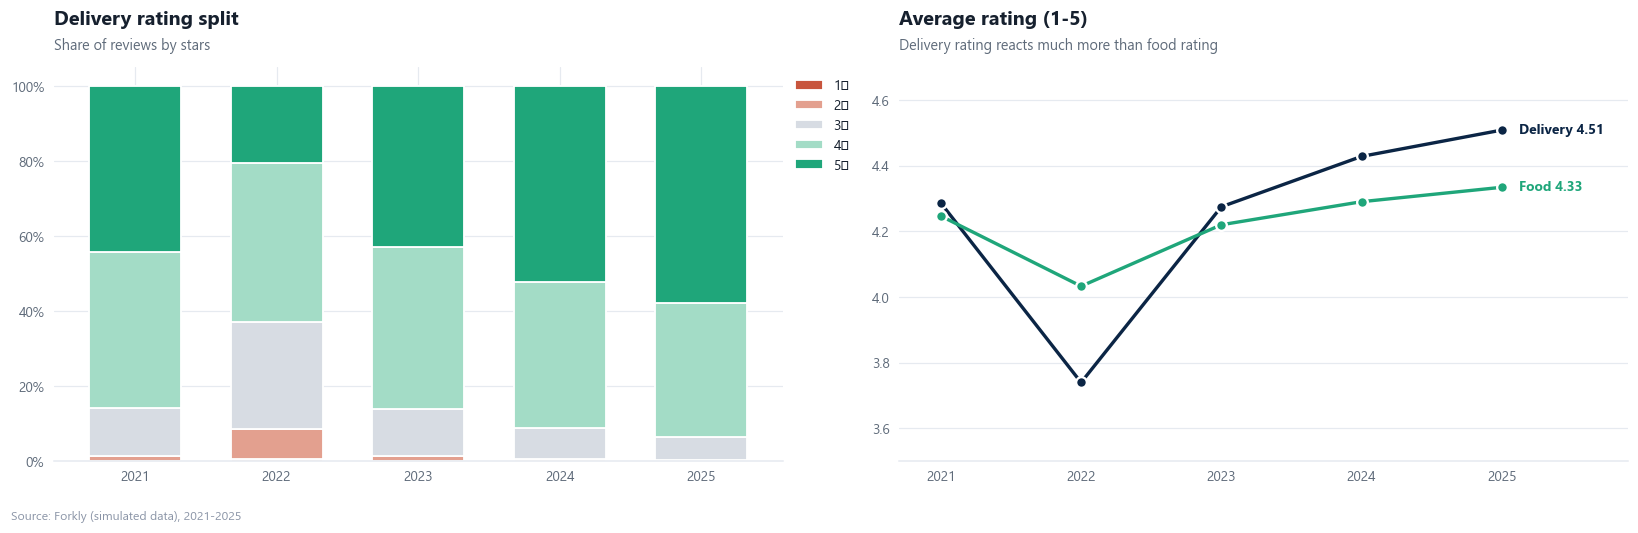

,food_rating,delivery_rating
year,,
2021,4.25,4.29
2022,4.03,3.74
2023,4.22,4.27
2024,4.29,4.43
2025,4.33,4.51


In [18]:
rv = done.dropna(subset=["delivery_rating"])
rv = rv.assign(delivery_rating=rv["delivery_rating"].astype(int))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
dist = (rv.groupby("year")["delivery_rating"].value_counts(normalize=True).unstack() * 100)[[1, 2, 3, 4, 5]]
dist.columns = [f"{c}★" for c in dist.columns]
dist.plot(kind="bar", stacked=True, ax=axes[0], width=0.65, edgecolor=BG, linewidth=1.2, color=RATING_COLORS)
axes[0].yaxis.set_major_formatter(pct); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(bbox_to_anchor=(1, 1), loc="upper left")
title(axes[0], "Delivery rating split", "Share of reviews by stars")

avg = rv.groupby("year")[["food_rating", "delivery_rating"]].mean()
for col, color, name in [("delivery_rating", NAVY, "Delivery"), ("food_rating", GREEN, "Food")]:
    axes[1].plot(avg.index, avg[col], marker="o", ms=7, color=color, label=name, markeredgecolor=BG, markeredgewidth=1.5)
    axes[1].text(avg.index[-1] + 0.12, avg[col].iloc[-1], f"{name} {avg[col].iloc[-1]:.2f}", va="center",
                 fontsize=9, color=color, weight="bold")
axes[1].set_xticks(avg.index); axes[1].set_ylim(3.5, 4.7); axes[1].set_xlim(2020.7, 2025.9)
title(axes[1], "Average rating (1-5)", "Delivery rating reacts much more than food rating")
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "02_ratings.png")
plt.show()
avg

## 11. Platform, payment and promotions

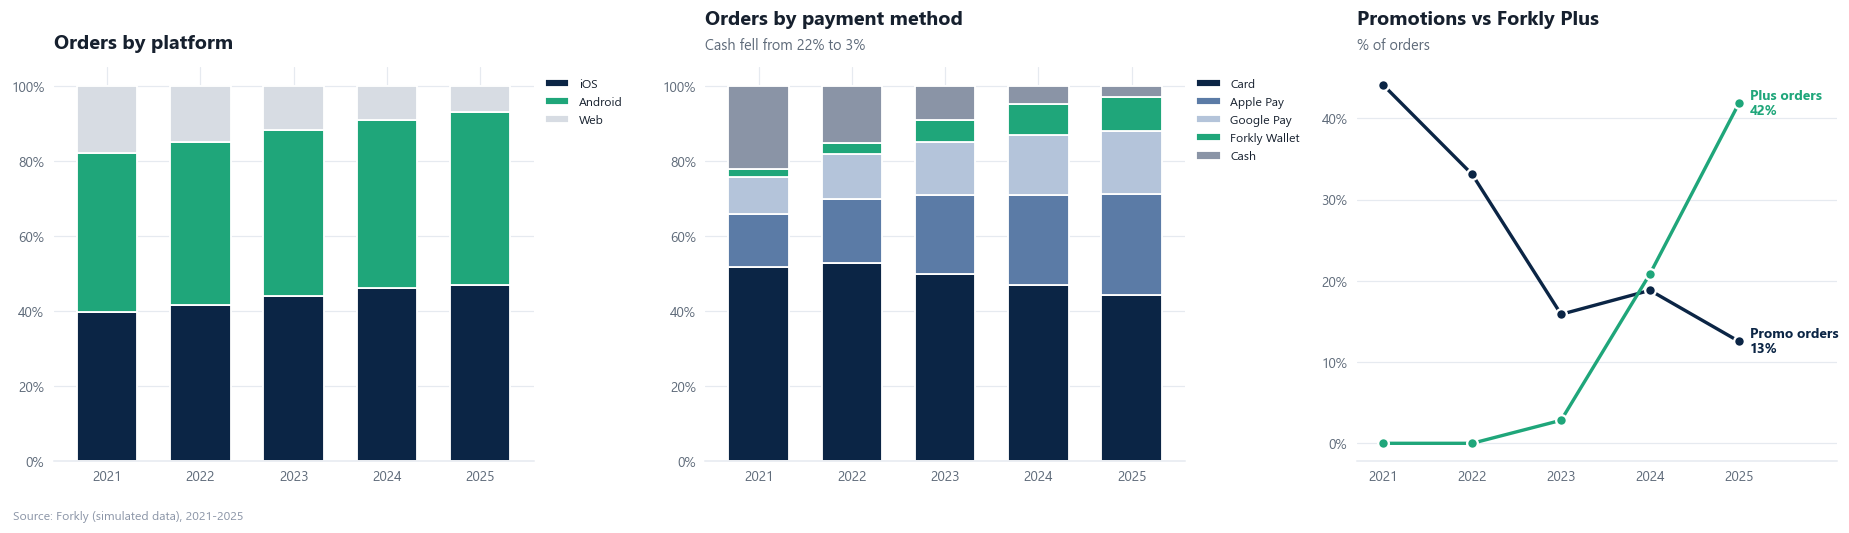

,has_promo,is_plus_order
year,,
2021,44.10,0.00
2022,33.10,0.00
2023,15.90,2.80
2024,18.80,20.90
2025,12.60,41.90


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
pl = pd.crosstab(orders["year"], orders["platform"], normalize="index")[["iOS", "Android", "Web"]] * 100
pl.plot(kind="bar", stacked=True, ax=axes[0], width=0.65, edgecolor=BG, linewidth=1.2, color=[NAVY, GREEN, GREY_LIGHT])
title(axes[0], "Orders by platform")

pm = pd.crosstab(orders["year"], orders["payment_method"], normalize="index")[
    ["Card", "Apple Pay", "Google Pay", "Forkly Wallet", "Cash"]] * 100
pm.plot(kind="bar", stacked=True, ax=axes[1], width=0.65, edgecolor=BG, linewidth=1.2,
        color=[NAVY, STEEL, NAVY_LIGHT, GREEN, GREY])
title(axes[1], "Orders by payment method", "Cash fell from 22% to 3%")
for ax in axes[:2]:
    ax.yaxis.set_major_formatter(pct); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
    ax.legend(bbox_to_anchor=(1, 1), loc="upper left", fontsize=8)

p = orders.groupby("year")[["has_promo", "is_plus_order"]].mean() * 100
for col, color, name in [("has_promo", NAVY, "Promo orders"), ("is_plus_order", GREEN, "Plus orders")]:
    axes[2].plot(p.index, p[col], marker="o", ms=7, color=color, markeredgecolor=BG, markeredgewidth=1.5)
    axes[2].text(p.index[-1] + 0.12, p[col].iloc[-1], f"{name}\n{p[col].iloc[-1]:.0f}%", va="center",
                 fontsize=9, color=color, weight="bold")
axes[2].yaxis.set_major_formatter(pct); axes[2].set_xticks(p.index); axes[2].set_xlim(2020.7, 2026.1)
title(axes[2], "Promotions vs Forkly Plus", "% of orders")
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "02_platform_payment_promo.png")
plt.show()
p.round(1)

## 12. Cancellations

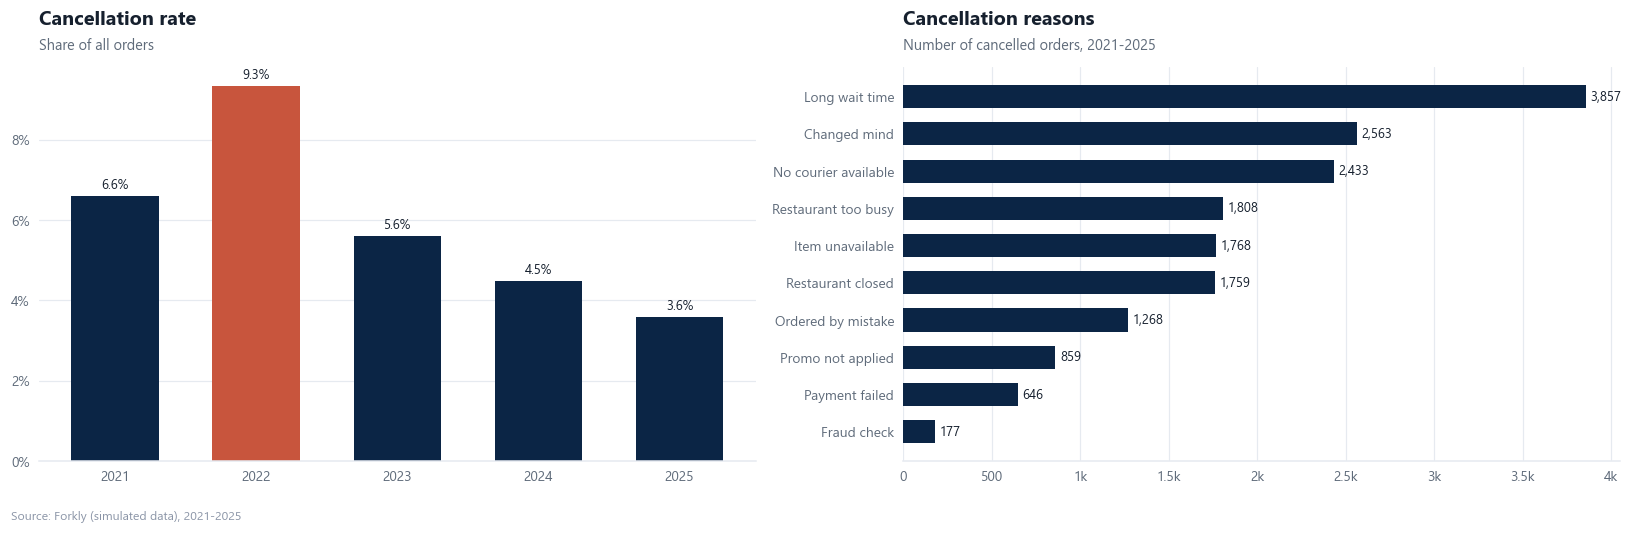

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
c = orders.groupby("year")["is_cancelled"].mean() * 100
bars = axes[0].bar(c.index, c.values, color=[ALERT if y == 2022 else NAVY for y in c.index], width=0.62)
label_bars(axes[0], bars, "{:.1f}%")
axes[0].yaxis.set_major_formatter(pct); axes[0].set_xticks(c.index)
title(axes[0], "Cancellation rate", "Share of all orders")

r = orders["cancellation_reason"].value_counts().sort_values()
bars = axes[1].barh(r.index, r.values, color=NAVY, height=0.62)
label_hbars(axes[1], bars, "{:,.0f}")
hbar_style(axes[1]); axes[1].xaxis.set_major_formatter(thousands)
title(axes[1], "Cancellation reasons", "Number of cancelled orders, 2021-2025")
source_note(fig)
plt.tight_layout()
save_fig(fig, FIG_DIR / "02_cancellations.png")
plt.show()

## 13. Correlations at order level

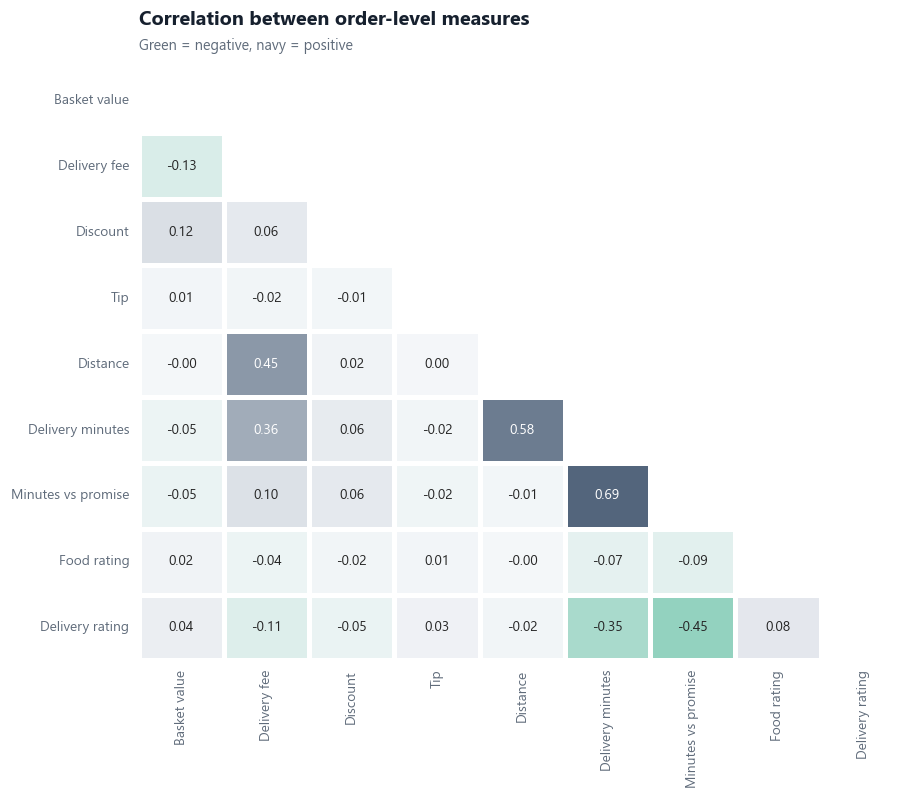

In [21]:
num = done[["items_subtotal", "delivery_fee", "discount_amount", "tip_amount", "distance_km",
            "delivery_minutes", "minutes_vs_promise", "food_rating", "delivery_rating"]].astype(float)
num.columns = ["Basket value", "Delivery fee", "Discount", "Tip", "Distance", "Delivery minutes",
               "Minutes vs promise", "Food rating", "Delivery rating"]
corr = num.corr()

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap=CMAP_DIVERGING, center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            linewidths=2, linecolor=BG, cbar=False, annot_kws={"fontsize": 9}, ax=ax)
clean_heatmap(ax)
title(ax, "Correlation between order-level measures", "Green = negative, navy = positive")
save_fig(fig, FIG_DIR / "02_correlation.png")
plt.show()

## 14. What the exploration shows

- **Volume:** 300,000 orders (282,862 not cancelled) from 42,026 ordering customers. Orders grew every year, fastest in 2022 (+62%), then slowed to +6% in 2023 and +8% in 2025.
- **Seasonality:** December is the busiest month every year (1.5-1.9x an average month), and July-August are the quietest. The first months of 2021 are boosted by lockdowns.
- **Time of day:** demand peaks at lunch (12:00-13:00) and even more at dinner (18:00-20:00). Weekends are about 30% busier than weekdays.
- **Order value:** the median basket rose from €18 to €24 between 2021 and 2025 (price inflation plus bigger baskets). Grocery baskets (~€30) are larger than restaurant baskets.
- **Cities:** Warsaw is the biggest market since 2023. The four launch cities peaked in 2022 and have been flat since.
- **Customers:** most customers are 35-54. Organic and referral signups grew while paid social and influencer signups fell after 2022.
- **Delivery:** average delivery time rose to 39 minutes in 2022, then fell every year to 31 minutes in 2025. E-bikes replaced bicycles and cars over the period. Rain and snow increase lateness.
- **Ratings:** the delivery rating dropped sharply in 2022 (3.74) and then reached 4.51 in 2025. Food ratings moved much less, so delivery problems are what customers react to.
- **Payments and promotions:** cash fell from 22% to 3% of orders, while Apple Pay and Google Pay grew. Promotions fell from 44% of orders to 13%, while Forkly Plus orders rose to 42%.
- **Correlations:** delivery rating is most related to minutes over the promised time (-0.45). Order value has almost no link to ratings.

These questions are picked up in **03_analysis**: what drives the margin turnaround, how retention changed, whether Plus and promotions pay off, and how much delivery problems cost in ratings and repeat orders.